## Проблема

Имеются наблюдения за бизонами: особенности поведения, физические характеристики, показатели активности. Однако определить точный возраст бизона напрямую практически сложно — животные улетают при виде человека.

Вес бизона — один из важных признаков, по которому можно судить о его возрасте.

## Задача ML

**Задача:** предсказать возраст летающего бизона по его физическим характеристикам и показателям активности.

**Объект:** летающий бизон (одна запись в датасете).

**Образ выходного результата модели:** число — возраст бизона (возраст в годах, непрерывная величина).

**Тип задачи:** регрессия.

# Описание исходных данных

## Семантика и ожидаемые типы признаков

| Признак | Семантика | Ожидаемый тип | Целевой |
|---|---|---|---|
| Type | Тип бизона (исторические данные / дикие / прирученные) | categorical (string) | Нет |
| Length | Длина бизона | float | Нет |
| Diameter | Диаметр бизона | float | Нет |
| Height | Высота бизона | float | Нет |
| Whole_weight | Общий вес бизона | float | Нет |
| Age | Возраст бизона (в годах) | float | **Да** |

## Формулы предметной области

Формулы предметной области для предсказания возраста в датасете не предоставлены. МЕМО даёт только подсказку о возможной двухэтапной схеме: сначала предсказать вес по признакам, затем возраст по весу. Конкретные формулы связи веса и возраста не указаны — они будут определяться моделью ML на этапе обучения.

In [1]:
import os
import pandas as pd
import numpy as np
import typing as t
import warnings
import missingno as msgn
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
warnings.filterwarnings('ignore')

seed = 42
np.random.seed(seed)


# 1. Предварительная обработка данных

## 1.1. Чтение и загрузка данных
Загружаем датасет с характеристиками летающих бизонов. Проверяем корректность загрузки: количество строк и столбцов, типы данных, наличие пропусков.

In [2]:
import os

home_dir = os.path.expanduser('~')
data_path = os.path.join(home_dir, 'OneDrive', 'Desktop', 'Studies_2026', 'ProgPractice', 'materials', 'datasets', '05_avatar.csv')

df = pd.read_csv(data_path, sep=',')

print(f"Размер датасета: {df.shape}")
print(f"\nПервые 5 строк:")
df.head()

Размер датасета: (4177, 6)

Первые 5 строк:


,Type,Length,Diameter,Height,Whole_weight,Age
0,исторические данные,22.75,18.25,9.5,514.0,15.0
1,исторические данные,17.50,13.25,9.0,225.5,7.0
2,прирученные бизоны,26.50,21.00,13.5,677.0,9.0
3,исторические данные,22.00,18.25,12.5,516.0,10.0
4,дикие бизоны,NaN,12.75,NaN,205.0,7.0


### Удаление строк с пропусками в таргете
Поскольку Age — целевой признак, строки с пропусками в нём нужно удалить. Удаляем до разделения на train/test, чтобы избежать смещения распределений.

In [3]:
df = df.dropna(subset=['Age'])

print(f"Размер после удаления пропусков в Age: {df.shape}")

Размер после удаления пропусков в Age: (3968, 6)


### Удаление строк с высокой концентрацией пропусков
Согласно лекции, строки с высокой концентрацией пропусков (>75-го перцентиля) могут стать аномальными после заполнения и подлежат удалению. Вычисляем долю пропусков по строкам и удаляем такие строки до разделения на train/test.

In [4]:
# Вычисляем долю пропусков по строкам
row_missing_ratio = df.isnull().mean(axis=1)
print(f"75-й перцентиль доли пропусков по строкам: {row_missing_ratio.quantile(0.75):.4f}")

# Удаляем строки с долей пропусков >75-го перцентиля
threshold = row_missing_ratio.quantile(0.75)
df = df[row_missing_ratio <= threshold]

print(f"Размер после удаления строк с высокой концентрацией пропусков: {df.shape}")

75-й перцентиль доли пропусков по строкам: 0.1667
Размер после удаления строк с высокой концентрацией пропусков: (3781, 6)


## 1.2. Разделение выборки на обучение и тест

In [5]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df, test_size=0.2, random_state=seed)

print(f"Train размер: {train_df.shape}")
print(f"Test размер: {test_df.shape}")

Train размер: (3024, 6)
Test размер: (757, 6)


## 1.3. Первичный анализ данных

Проводим анализ только на train-выборке, чтобы избежать утечки данных. Проверяем:
- Типы данных 
- Количество уникальных значений
- Наличие пропусков в каждом признаке
- Основные статистики

In [6]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3024 entries, 3559 to 3513
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Type          3024 non-null   object 
 1   Length        2714 non-null   float64
 2   Diameter      2791 non-null   float64
 3   Height        2646 non-null   float64
 4   Whole_weight  3024 non-null   float64
 5   Age           3024 non-null   float64
dtypes: float64(5), object(1)
memory usage: 165.4+ KB


In [7]:
train_df.nunique()

Type               3
Length           131
Diameter         106
Height            50
Whole_weight    2021
Age               27
dtype: int64

In [8]:
train_df.describe()

,Length,Diameter,Height,Whole_weight,Age
count,2714.000000,2791.000000,2646.000000,3024.000000,3024.000000
mean,26.195652,20.422429,13.991119,827.771495,9.917328
std,5.949148,4.913985,4.348523,483.497631,3.209074
min,5.500000,4.500000,0.000000,8.000000,2.000000
25%,22.500000,17.500000,11.500000,447.000000,8.000000
50%,27.250000,21.250000,14.000000,796.250000,10.000000
75%,30.750000,24.000000,16.500000,1151.000000,11.000000
max,40.000000,31.500000,113.000000,2825.500000,29.000000


In [9]:
print("Уникальные значения Type:")
print(train_df['Type'].value_counts())

Уникальные значения Type:
Type
исторические данные    1085
дикие бизоны            988
прирученные бизоны      951
Name: count, dtype: int64


## 1.4. Обработка вещественных признаков

### Анализ пропусков
Сначала анализируем пропуски в вещественных признаках. Визуализируем матрицу пропусков и определяем долю пропусков по признакам и по строкам.

<Axes: >

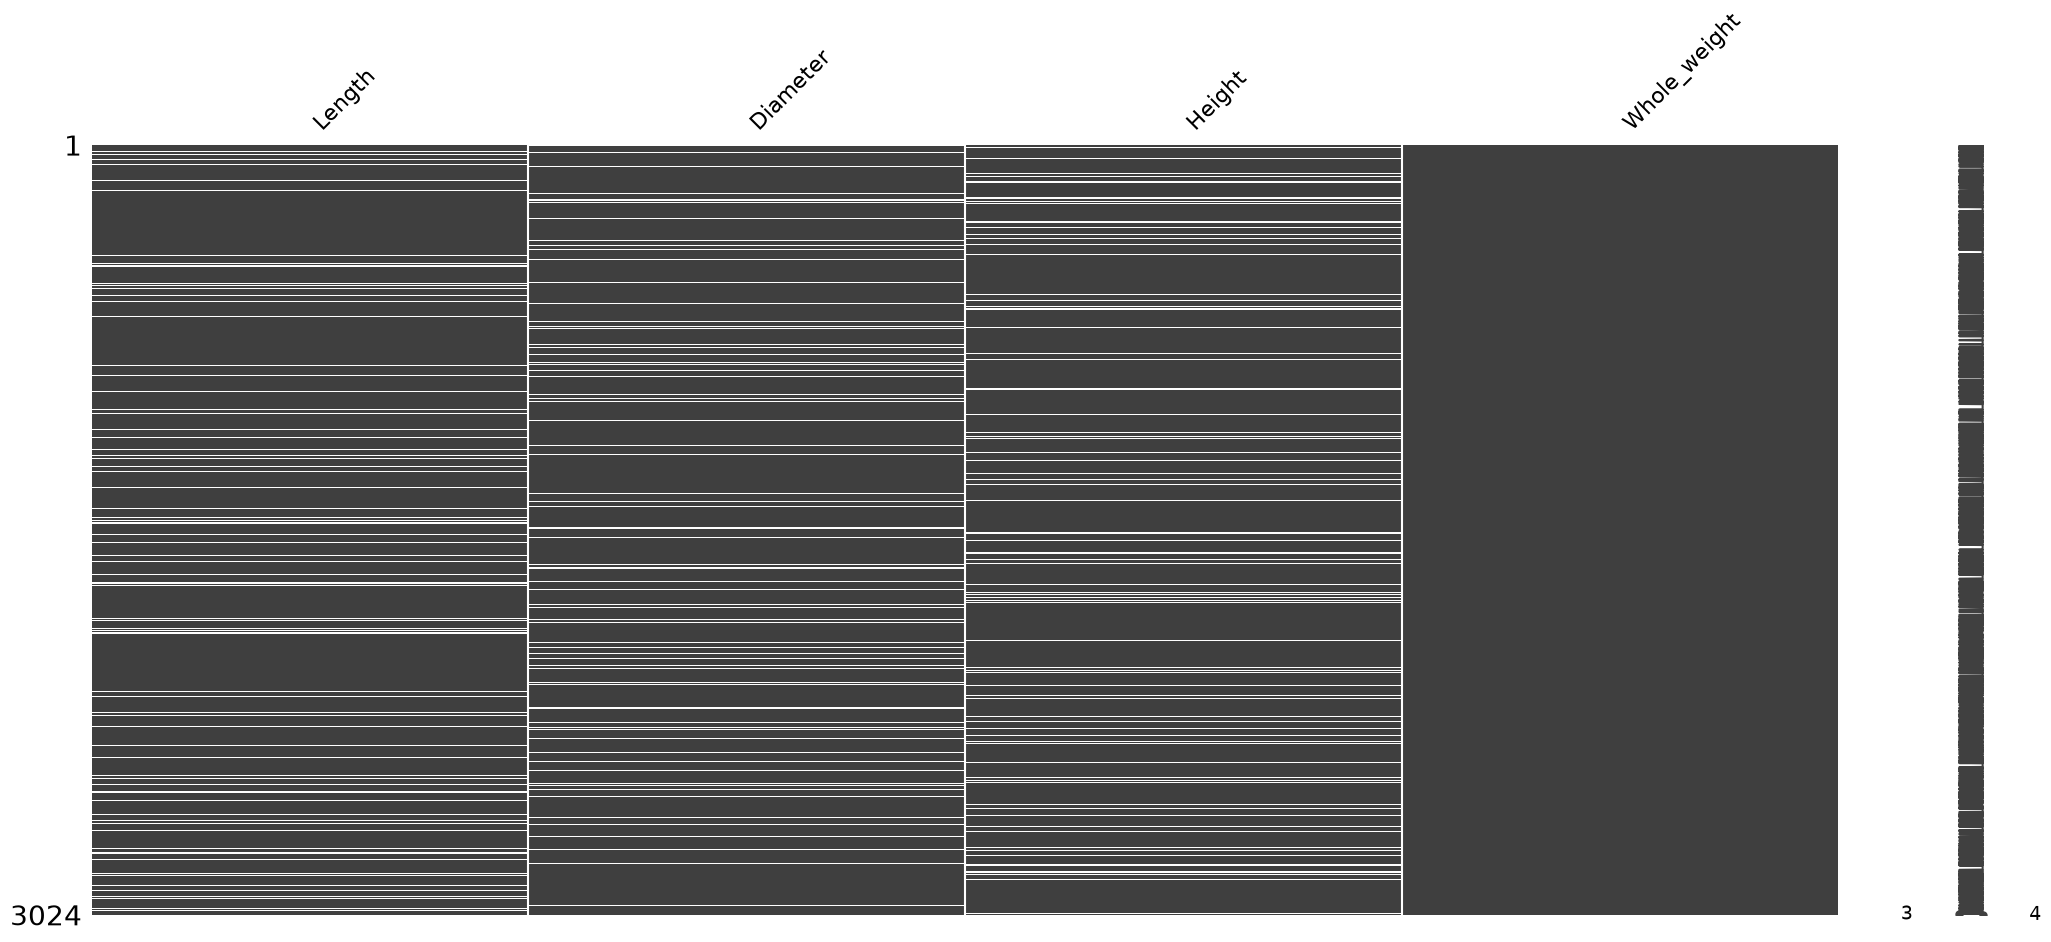

In [10]:
# Выделяем только вещественные признаки (исключая таргет Age)
numeric_cols = train_df.select_dtypes(include=['float64', 'int64']).columns.tolist()
numeric_cols = [col for col in numeric_cols if col != 'Age']

# Визуализация пропусков
msgn.matrix(train_df[numeric_cols])

### Доля пропусков по признакам и по строкам
Выводим долю пропусков для каждого вещественного признака, чтобы решить, какие признаки можно удалить (если >50-70%). Также проверяем долю пропусков по строкам после удаления.

In [11]:
# Доля пропусков по признакам
missing_ratio = train_df[numeric_cols].isnull().mean()
print("Доля пропусков по признакам:")
print(missing_ratio)

# Доля пропусков по строкам
row_missing_ratio_train = train_df.isnull().mean(axis=1)
print(f"\nДоля пропусков по строкам (макс): {row_missing_ratio_train.max():.4f}")
print(f"Доля пропусков по строкам (75-й перцентиль): {row_missing_ratio_train.quantile(0.75):.4f}")

Доля пропусков по признакам:
Length          0.102513
Diameter        0.077050
Height          0.125000
Whole_weight    0.000000
dtype: float64

Доля пропусков по строкам (макс): 0.1667
Доля пропусков по строкам (75-й перцентиль): 0.1667


### Удаление признаков с высокой долей пропусков
Согласно лекции, признаки с >50-70% пропусков можно считать неинформативными и удалить. Выводим, какие признаки попадают под это правило.

In [12]:
# Признаки с >50% пропусков
high_missing = missing_ratio[missing_ratio > 0.5].index.tolist()
print(f"Признаки с >50% пропусков: {high_missing}")

# В данном случае таких признаков нет, но если бы были, мы бы их удалили
# numeric_cols = [col for col in numeric_cols if col not in high_missing]

Признаки с >50% пропусков: []


### Заполнение пропусков в вещественных признаках
Заполняем пропуски статистическими методами (mean/median). Выбор значения обосновываем анализом распределений и KL-дивергенцией.

In [13]:
from scipy.stats import entropy

def calc_kl_divergence(original: np.ndarray, filled: np.ndarray, bins: int = 30) -> float:
    """Вычисление KL-дивергенции между двумя распределениями.
    
    Чем ближе к 0, тем больше распределения похожи.
    """
    # Строим гистограммы с одинаковыми бинами
    hist_orig, _ = np.histogram(original, bins=bins, density=True)
    hist_filled, _ = np.histogram(filled, bins=bins, density=True)
    
    # Добавляем малую константу, чтобы избежать деления на 0
    epsilon = 1e-10
    hist_orig = hist_orig + epsilon
    hist_filled = hist_filled + epsilon
    
    # Нормализуем
    hist_orig = hist_orig / hist_orig.sum()
    hist_filled = hist_filled / hist_filled.sum()
    
    # KL-дивергенция
    kl = entropy(hist_filled, hist_orig)
    return kl

In [14]:
# Для каждого признака с пропусками тестируем заполнение mean и median
fillna_rule = {}

for col in numeric_cols:
    if train_df[col].isnull().sum() > 0:
        original = train_df[col].dropna().values
        
        # Заполнение mean
        filled_mean = train_df[col].fillna(train_df[col].mean()).values
        kl_mean = calc_kl_divergence(original, filled_mean)
        
        # Заполнение median
        filled_median = train_df[col].fillna(train_df[col].median()).values
        kl_median = calc_kl_divergence(original, filled_median)
        
        print(f"{col}: KL(mean)={kl_mean:.4f}, KL(median)={kl_median:.4f}")
        
        # Выбираем значение с меньшей KL-дивергенцией
        if kl_mean < kl_median:
            fillna_rule[col] = train_df[col].mean()
            print(f"  -> выбрано mean")
        else:
            fillna_rule[col] = train_df[col].median()
            print(f"  -> выбрано median")

print(f"\nПравило заполнения: {fillna_rule}")

Length: KL(mean)=0.0590, KL(median)=0.0518
  -> выбрано median
Diameter: KL(mean)=0.0361, KL(median)=0.0316
  -> выбрано median
Height: KL(mean)=0.0132, KL(median)=0.0132
  -> выбрано median

Правило заполнения: {'Length': np.float64(27.250000000000004), 'Diameter': np.float64(21.25), 'Height': np.float64(14.000000000000002)}


In [15]:
# Применяем правило заполнения к train и test
for col, value in fillna_rule.items():
    train_df[col] = train_df[col].fillna(value)
    test_df[col] = test_df[col].fillna(value)

print("Пропуски заполнены.")
print(f"Пропуски в train после заполнения: {train_df[numeric_cols].isnull().sum().sum()}")
print(f"Пропуски в test после заполнения: {test_df[numeric_cols].isnull().sum().sum()}")

Пропуски заполнены.
Пропуски в train после заполнения: 0
Пропуски в test после заполнения: 0


## 1.5. Кодирование категориальных признаков

### Проверка категорий в train
Проверяем, что все категории из оригинального датасета присутствуют в train. Если какие-то категории отсутствуют в train, это нужно учесть в кодировщике (handle_unknown='ignore').

In [16]:
# Выделяем категориальные признаки
cat_cols = train_df.select_dtypes(include=['object']).columns.tolist()
print(f"Категориальные признаки: {cat_cols}")

# Проверяем, что все категории есть в train
for col in cat_cols:
    df_cats = set(df[col].dropna().unique())
    train_cats = set(train_df[col].dropna().unique())
    missing_cats = df_cats - train_cats
    if missing_cats:
        print(f"{col}: категории, отсутствующие в train: {missing_cats}")
    else:
        print(f"{col}: все категории присутствуют в train")

Категориальные признаки: ['Type']
Type: все категории присутствуют в train


### One-Hot кодирование
Признак Type — равнозначные категории (исторические данные / дикие / прирученные), используем OneHotEncoder. Параметр handle_unknown='ignore' позволяет корректно обрабатывать новые категории в test (если они вдруг появятся).

In [17]:
from sklearn.preprocessing import OneHotEncoder

# Инициализируем кодировщик
encoder = OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore')

# Fit на train, transform на train и test
train_encoded = encoder.fit_transform(train_df[cat_cols])
test_encoded = encoder.transform(test_df[cat_cols])

# Получаем имена новых признаков
encoded_feature_names = encoder.get_feature_names_out(cat_cols)
print(f"Новые признаки после кодирования: {encoded_feature_names.tolist()}")

# Создаём DataFrame с закодированными признаками
train_encoded_df = pd.DataFrame(train_encoded, columns=encoded_feature_names, index=train_df.index)
test_encoded_df = pd.DataFrame(test_encoded, columns=encoded_feature_names, index=test_df.index)

# Удаляем исходные категориальные признаки и добавляем закодированные
train_df = train_df.drop(columns=cat_cols).join(train_encoded_df)
test_df = test_df.drop(columns=cat_cols).join(test_encoded_df)

print(f"\nРазмер train после кодирования: {train_df.shape}")
print(f"Размер test после кодирования: {test_df.shape}")

Новые признаки после кодирования: ['Type_исторические данные', 'Type_прирученные бизоны']

Размер train после кодирования: (3024, 7)
Размер test после кодирования: (757, 7)


## 1.6. Детекция выбросов и аномалий в данных

По карте ЛР 3 и лекции 3: сначала выбросы (гистограммы/boxplot → IQR и Z-score → пересечение → удаление), затем аномалии на очищенном срезе (IForest ∩ OCSVM → UMAP → удаление).

Работаем только с **непрерывными** признаками (`Length`, `Diameter`, `Height`, `Whole_weight`). One-hot столбцы `Type` и таргет `Age` в детекцию не подаём. Статистики и модели считаем на **train**, на test применяем те же границы / `predict`.


### 1.6.1. Визуализация выбросов

Строим гистограммы (с границами IQR и Z-score), KDE и ящики с усами по непрерывным признакам train. Цель — увидеть асимметрию и кандидатов на выбросы (в INDEX для Аватара отмечен `Height`: max 113 при медиане ≈ 10).


Непрерывные признаки для детекции: ['Length', 'Diameter', 'Height', 'Whole_weight']


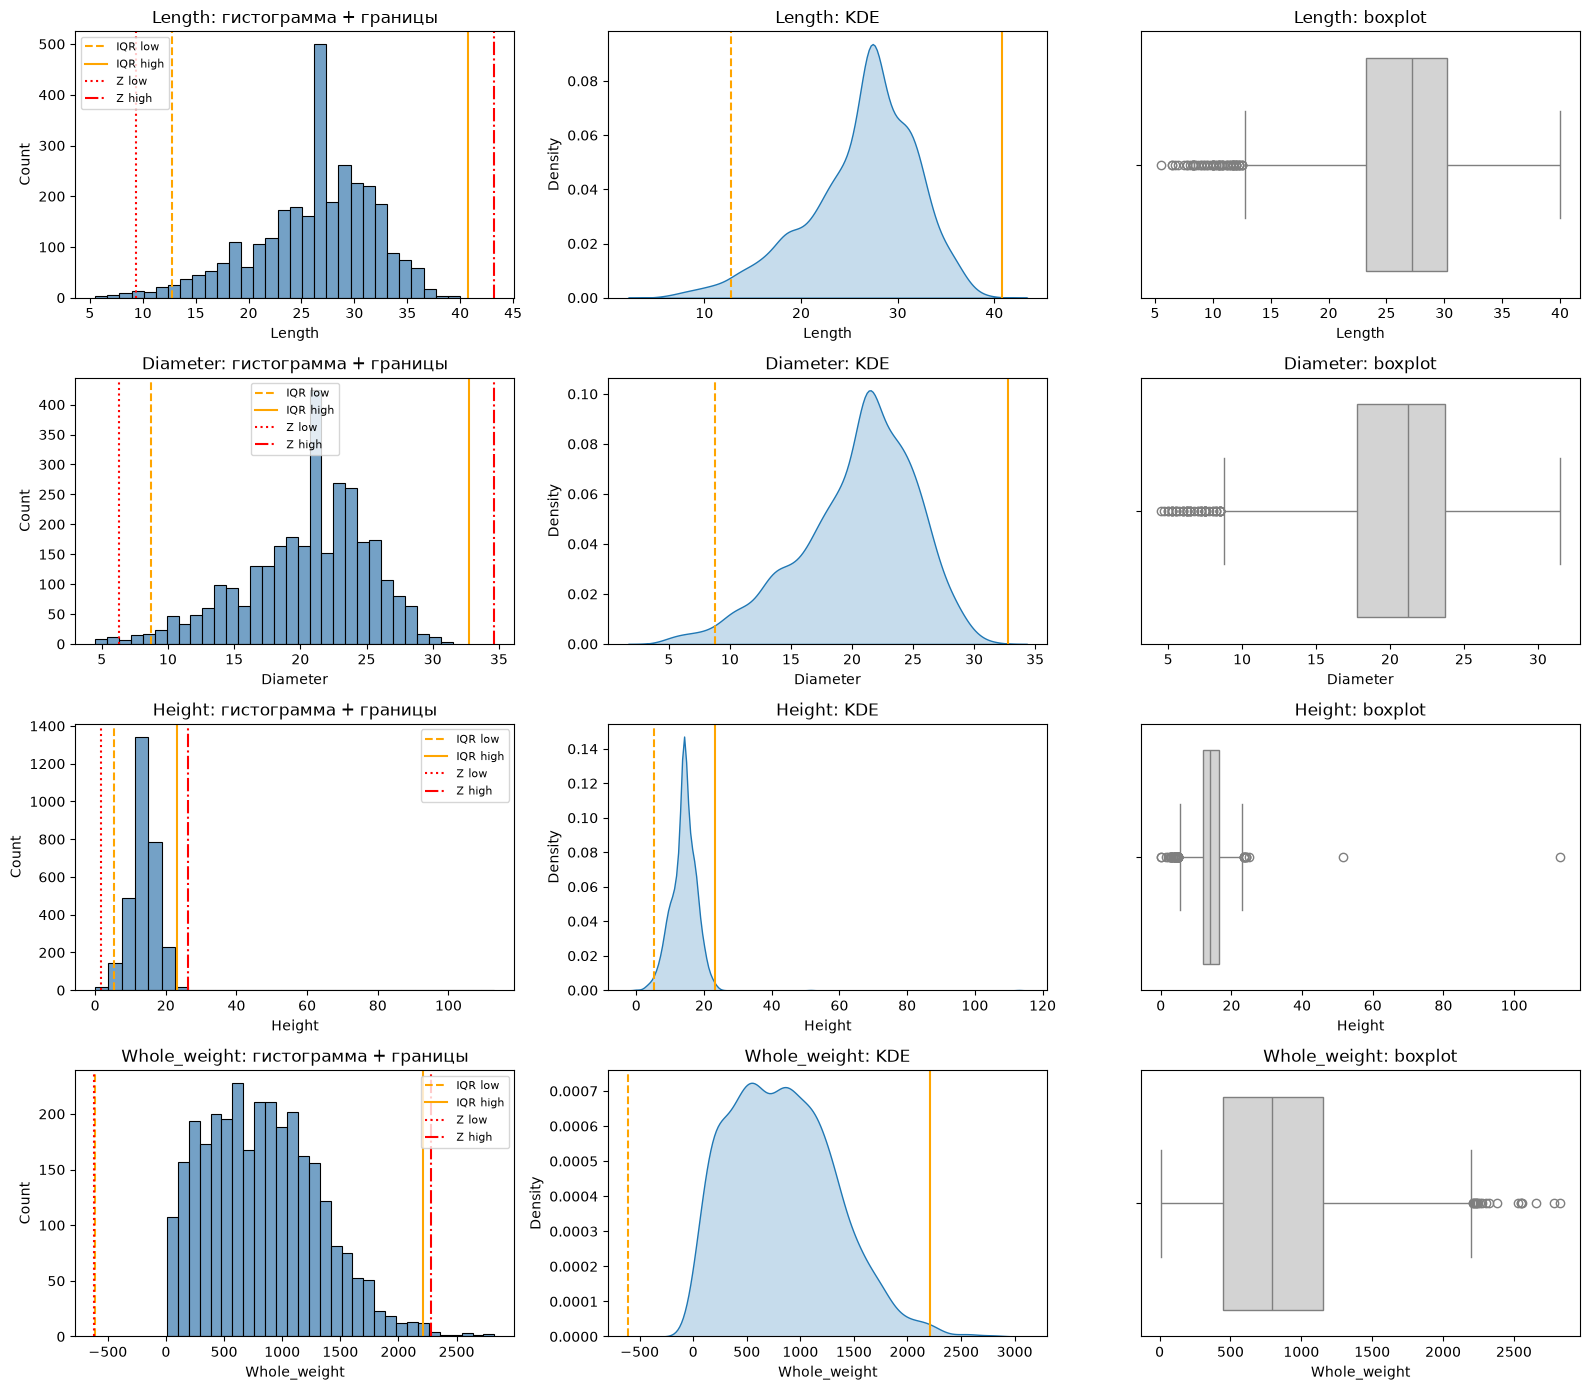

Length: IQR bounds=(np.float64(12.75), np.float64(40.75)), z μ=26.3037, σ=5.6440
Diameter: IQR bounds=(np.float64(8.75), np.float64(32.75)), z μ=20.4862, σ=4.7252
Height: IQR bounds=(np.float64(5.25), np.float64(23.25)), z μ=13.9922, σ=4.0669
Whole_weight: IQR bounds=(np.float64(-609.0), np.float64(2207.0)), z μ=827.7715, σ=483.4177


In [18]:
continuous_cols = [c for c in ['Length', 'Diameter', 'Height', 'Whole_weight'] if c in train_df.columns]
print('Непрерывные признаки для детекции:', continuous_cols)

X_train_cont = train_df[continuous_cols].copy()
X_test_cont = test_df[continuous_cols].copy()

# Границы IQR и Z-score (|z|>3) — только по train
iqr_bounds = {}
z_params = {}
Z_THRESHOLD = 3.0

for col in continuous_cols:
    s = X_train_cont[col]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    iqr_bounds[col] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)
    mu, sigma = s.mean(), s.std(ddof=0)
    z_params[col] = (mu, sigma if sigma != 0 else 1.0)

n = len(continuous_cols)
fig, axes = plt.subplots(n, 3, figsize=(16, 3.5 * n))
for i, col in enumerate(continuous_cols):
    lo_iqr, hi_iqr = iqr_bounds[col]
    mu, sigma = z_params[col]
    lo_z, hi_z = mu - Z_THRESHOLD * sigma, mu + Z_THRESHOLD * sigma

    sns.histplot(X_train_cont[col], ax=axes[i, 0], kde=False, bins=30, color='steelblue')
    axes[i, 0].axvline(lo_iqr, color='orange', linestyle='--', label='IQR low')
    axes[i, 0].axvline(hi_iqr, color='orange', linestyle='-', label='IQR high')
    axes[i, 0].axvline(lo_z, color='red', linestyle=':', label='Z low')
    axes[i, 0].axvline(hi_z, color='red', linestyle='-.', label='Z high')
    axes[i, 0].set_title(f'{col}: гистограмма + границы')
    axes[i, 0].legend(fontsize=8)

    sns.kdeplot(X_train_cont[col], ax=axes[i, 1], fill=True)
    axes[i, 1].axvline(lo_iqr, color='orange', linestyle='--')
    axes[i, 1].axvline(hi_iqr, color='orange', linestyle='-')
    axes[i, 1].set_title(f'{col}: KDE')

    sns.boxplot(x=X_train_cont[col], ax=axes[i, 2], color='lightgray')
    axes[i, 2].set_title(f'{col}: boxplot')

plt.tight_layout()
plt.show()

for col in continuous_cols:
    print(f"{col}: IQR bounds={iqr_bounds[col]}, z μ={z_params[col][0]:.4f}, σ={z_params[col][1]:.4f}")


### 1.6.2. Детекция выбросов: IQR и Z-score

- **IQR** (ноутбук лекции 3): выброс признака вне [Q1−1.5·IQR; Q3+1.5·IQR] (в markdown лекции верхняя граница ошибочно через Q1 — используем Q3, как в коде образца).
- **Z-score**: z=(x−μ)/σ, порог |z|>3 — в слайдах есть только название метода, формула и порог **вне курса** (общая статистика).
- Строка помечается методом, если выброс **хотя бы в одном** continuous-признаке (`np.any`, как в образце).
- Удаляем **пересечение** индексов IQR ∩ Z-score. Объекты, помеченные только одним методом, оставляем: одного метода недостаточно для уверенного удаления (критерий вики — удалить или обосновать; оставляем non-intersection с этим обоснованием).


In [19]:
def flag_outliers_iqr(df: pd.DataFrame, bounds: dict) -> pd.Series:
    flags = pd.DataFrame({
        col: (df[col] < lo) | (df[col] > hi)
        for col, (lo, hi) in bounds.items()
    }, index=df.index)
    return flags.any(axis=1)


def flag_outliers_zscore(df: pd.DataFrame, params: dict, threshold: float = Z_THRESHOLD) -> pd.Series:
    flags = pd.DataFrame({
        col: ((df[col] - mu) / sigma).abs() > threshold
        for col, (mu, sigma) in params.items()
    }, index=df.index)
    return flags.any(axis=1)


train_out_iqr = flag_outliers_iqr(X_train_cont, iqr_bounds)
train_out_z = flag_outliers_zscore(X_train_cont, z_params)
train_out_both = train_out_iqr & train_out_z

test_out_iqr = flag_outliers_iqr(X_test_cont, iqr_bounds)
test_out_z = flag_outliers_zscore(X_test_cont, z_params)
test_out_both = test_out_iqr & test_out_z

print(f'Train IQR&~Z: {int((train_out_iqr & ~train_out_z).sum())}')
print(f'Train Z&~IQR: {int((train_out_z & ~train_out_iqr).sum())}')
print(f'Train IQR∩Z (удаляем): {int(train_out_both.sum())}')
print(f'Test IQR∩Z (удаляем теми же границами train): {int(test_out_both.sum())}')
if int(train_out_both.sum()) == int(train_out_z.sum()):
    print('На train все Z-выбросы входят в IQR (Z ⊆ IQR); пересечение = множество Z.')

if train_out_both.any():
    print('\nПримеры train IQR∩Z:')
    display(train_df.loc[train_out_both, continuous_cols + ['Age']].head(10))

train_df = train_df.loc[~train_out_both].copy()
test_df = test_df.loc[~test_out_both].copy()
X_train_cont = train_df[continuous_cols].copy()
X_test_cont = test_df[continuous_cols].copy()

print(f'\nПосле удаления выбросов: train={train_df.shape}, test={test_df.shape}')


Train IQR&~Z: 64
Train Z&~IQR: 0
Train IQR∩Z (удаляем): 39
Test IQR∩Z (удаляем теми же границами train): 13
На train все Z-выбросы входят в IQR (Z ⊆ IQR); пересечение = множество Z.

Примеры train IQR∩Z:


,Length,Diameter,Height,Whole_weight,Age
3837,8.50,5.25,3.5,34.0,4.0
1824,9.25,21.25,4.0,27.0,5.0
2115,9.00,6.50,14.0,27.5,3.0
1051,36.75,30.00,22.0,2555.0,11.0
525,8.75,6.25,4.0,24.0,4.0
1053,9.25,6.50,14.0,29.0,4.0
237,6.50,5.00,3.0,13.0,3.0
2343,8.50,6.25,5.5,23.5,6.0
1417,35.25,28.25,51.5,2210.0,10.0
1986,6.75,6.50,4.0,29.0,4.0



После удаления выбросов: train=(2985, 7), test=(744, 7)


### 1.6.3. Детекция аномалий: Isolation Forest и OCSVM

После очистки от согласованных выбросов ищем аномальные **объекты** в пространстве непрерывных признаков (pyod, как в ноутбуке лекции 3). Два алгоритма с разной геометрией: Isolation Forest и One-Class SVM. Аномальными считаем объекты в **пересечении** предсказаний. Визуализация — UMAP → 2D.

По умолчанию у IForest/OCSVM в pyod contamination≈0.1: порог decision score подбирается **на train**. На test тот же порог применяется через predict, поэтому доля аномалий на test может отличаться (в т.ч. быть выше) — это не утечка и не переобучение на test, а следствие сдвига распределения относительно калибровки train.


Train IForest: 299, OCSVM: 299, пересечение: 33 (1.1%)
Test пересечение: 75 (10.1%) — порог contamination зафиксирован на train


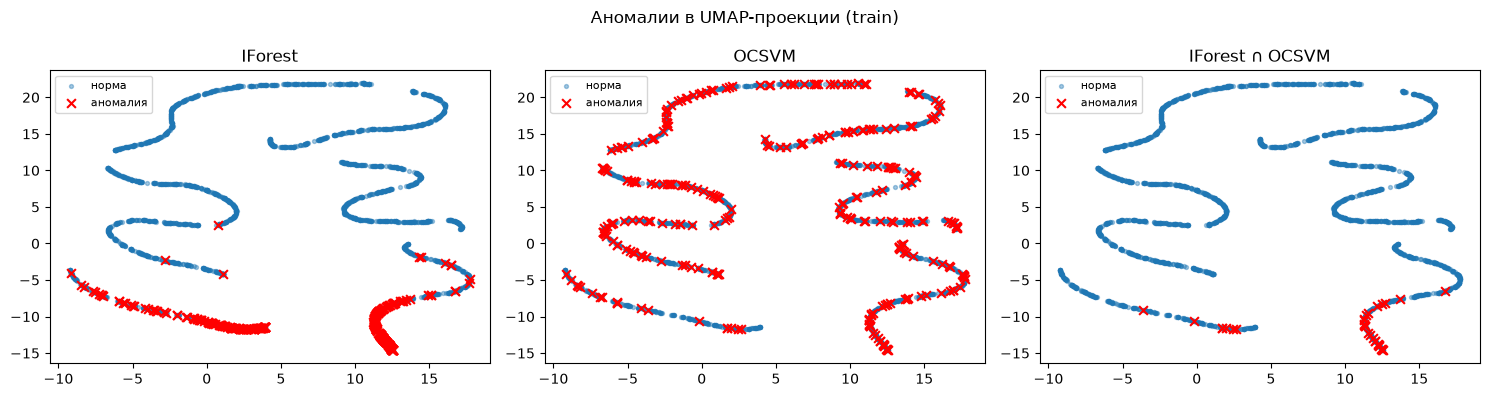

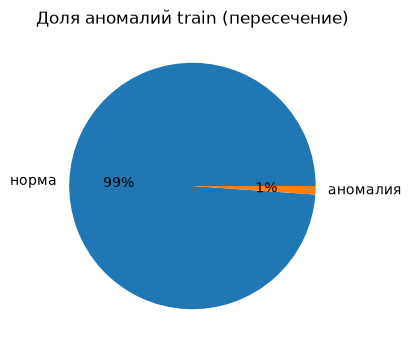

Примеры аномалий (пересечение):


,Length,Diameter,Height,Whole_weight,Age
538,13.75,10.25,14.0,94.0,5.0
4021,34.50,29.00,19.5,1658.0,10.0
2001,18.00,21.25,8.5,218.5,6.0
233,13.75,10.75,14.0,115.5,7.0
2455,11.75,8.50,6.5,62.5,6.0
464,12.75,9.75,14.0,73.5,6.0
1055,9.75,6.75,4.0,32.5,4.0
3179,13.50,9.75,7.0,102.0,8.0
3105,14.50,10.75,6.0,111.5,5.0
1996,16.25,12.50,7.0,174.5,7.0


Интерпретация: в пересечении часто крайние комбинации масштаба (малый/крупный Whole_weight при нетипичном Length/Height), а не одиночный Height-выброс — оба алгоритма видят точку далеко от плотного облака в 4D.
После удаления аномалий: train=(2952, 7), test=(669, 7)


In [20]:
from pyod.models.iforest import IForest
from pyod.models.ocsvm import OCSVM
from umap import UMAP

isf = IForest(random_state=seed).fit(X_train_cont.values)
ocsvm = OCSVM().fit(X_train_cont.values)

train_isf = isf.predict(X_train_cont.values).astype(bool)
train_ocsvm = ocsvm.predict(X_train_cont.values).astype(bool)
train_anom = train_isf & train_ocsvm

test_isf = isf.predict(X_test_cont.values).astype(bool)
test_ocsvm = ocsvm.predict(X_test_cont.values).astype(bool)
test_anom = test_isf & test_ocsvm

print(f'Train IForest: {train_isf.sum()}, OCSVM: {train_ocsvm.sum()}, пересечение: {train_anom.sum()} ({100 * train_anom.mean():.1f}%)')
print(f'Test пересечение: {test_anom.sum()} ({100 * test_anom.mean():.1f}%) — порог contamination зафиксирован на train')

umap_model = UMAP(n_components=2, random_state=seed)
X_train_2d = umap_model.fit_transform(X_train_cont.values)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, mask, title in [
    (axes[0], train_isf, 'IForest'),
    (axes[1], train_ocsvm, 'OCSVM'),
    (axes[2], train_anom, 'IForest ∩ OCSVM'),
]:
    ax.scatter(X_train_2d[:, 0], X_train_2d[:, 1], s=8, alpha=0.4, label='норма')
    if mask.any():
        ax.scatter(X_train_2d[mask, 0], X_train_2d[mask, 1], c='red', marker='x', s=40, label='аномалия')
    ax.set_title(title)
    ax.legend(fontsize=8)
plt.suptitle('Аномалии в UMAP-проекции (train)')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(4, 4))
labels = ['норма', 'аномалия']
sizes = [int((~train_anom).sum()), int(train_anom.sum())]
ax.pie(sizes, labels=labels, autopct='%1.0f%%')
ax.set_title('Доля аномалий train (пересечение)')
plt.show()

if train_anom.any():
    print('Примеры аномалий (пересечение):')
    display(train_df.loc[train_anom, continuous_cols + ['Age']].head(10))
    print('Интерпретация: в пересечении часто крайние комбинации масштаба (малый/крупный Whole_weight при нетипичном Length/Height), а не одиночный Height-выброс — оба алгоритма видят точку далеко от плотного облака в 4D.')

train_df = train_df.loc[~train_anom].copy()
test_df = test_df.loc[~test_anom].copy()
print(f'После удаления аномалий: train={train_df.shape}, test={test_df.shape}')


### 1.6.4. Интерпретация решения об удалении

- Height с экстремальными значениями (в сырых данных до сотен при медиане ≈ 10) выглядит как ошибка измерения/записи; после IQR∩Z максимум Height падает до разумного диапазона.
- На train множество Z-выбросов оказалось вложено в IQR (Z ⊆ IQR): пересечение = все Z-строки; отдельно остаются IQR-only — их не удаляем, потому что Z-score их не подтвердил.
- Удаляем только **пересечение** методов: если алгоритмы не согласны, объект оставляем (критерий вики — удалить или обосновать).
- Аномалии после очистки выбросов — объекты на краю 4D-облака (типично диспропорция Whole_weight относительно Length/Diameter/Height); удаляем только IForest∩OCSVM.
- Доля аномалий на test может быть выше train: contamination и порог score калибруются на train и переносятся на test без пересчёта.


## 1.7. Подведение итогов раздела 1

К концу раздела 1: данные загружены, пропуски обработаны, категории закодированы, согласованные выбросы и аномалии удалены. Train/test готовы к генерации признаков (ЛР 4).


In [21]:
print(f"Итоговый размер train: {train_df.shape}")
print(f"Итоговый размер test: {test_df.shape}")
print(f"Пропуски train: {train_df.isnull().sum().sum()}, test: {test_df.isnull().sum().sum()}")
print("Столбцы:", train_df.columns.tolist())
print(train_df.describe())


Итоговый размер train: (2952, 7)
Итоговый размер test: (669, 7)
Пропуски train: 0, test: 0
Столбцы: ['Length', 'Diameter', 'Height', 'Whole_weight', 'Age', 'Type_исторические данные', 'Type_прирученные бизоны']
            Length     Diameter       Height  Whole_weight         Age  \
count  2952.000000  2952.000000  2952.000000   2952.000000  2952.00000   
mean     26.487636    20.633977    14.040989    832.252371     9.99187   
std       5.302619     4.442601     3.399800    464.720288     3.15078   
min       9.500000     6.500000     2.500000     31.500000     3.00000   
25%      23.500000    17.750000    12.000000    459.375000     8.00000   
50%      27.250000    21.250000    14.000000    803.750000    10.00000   
75%      30.250000    23.750000    16.500000   1150.625000    11.00000   
max      38.500000    30.750000    24.000000   2273.000000    29.00000   

       Type_исторические данные  Type_прирученные бизоны  
count               2952.000000              2952.000000  
mean

## Production

Чистый воспроизводимый пайплайн предобработки ЛР 1–3 (fit только на train).


In [22]:
# ==================== PRODUCTION BLOCK ====================
from scipy.stats import entropy
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from pyod.models.iforest import IForest
from pyod.models.ocsvm import OCSVM

home_dir = os.path.expanduser('~')
data_path = os.path.join(home_dir, 'OneDrive', 'Desktop', 'Studies_2026', 'ProgPractice', 'materials', 'datasets', '05_avatar.csv')
df = pd.read_csv(data_path, sep=',')

df = df.dropna(subset=['Age'])
row_missing_ratio = df.isnull().mean(axis=1)
df = df[row_missing_ratio <= row_missing_ratio.quantile(0.75)]

seed = 42
train_df, test_df = train_test_split(df, test_size=0.2, random_state=seed)

numeric_cols = [c for c in train_df.select_dtypes(include=['float64', 'int64']).columns if c != 'Age']
cat_cols = train_df.select_dtypes(include=['object']).columns.tolist()

fillna_rule = {}
for col in numeric_cols:
    if train_df[col].isnull().sum() > 0:
        original = train_df[col].dropna().values
        filled_mean = train_df[col].fillna(train_df[col].mean()).values
        filled_median = train_df[col].fillna(train_df[col].median()).values
        hist_orig, _ = np.histogram(original, bins=30, density=True)
        hist_mean, _ = np.histogram(filled_mean, bins=30, density=True)
        hist_median, _ = np.histogram(filled_median, bins=30, density=True)
        eps = 1e-10
        hist_orig = (hist_orig + eps) / (hist_orig + eps).sum()
        hist_mean = (hist_mean + eps) / (hist_mean + eps).sum()
        hist_median = (hist_median + eps) / (hist_median + eps).sum()
        fillna_rule[col] = train_df[col].mean() if entropy(hist_mean, hist_orig) < entropy(hist_median, hist_orig) else train_df[col].median()

for col, value in fillna_rule.items():
    train_df[col] = train_df[col].fillna(value)
    test_df[col] = test_df[col].fillna(value)

encoder = OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore')
train_encoded = encoder.fit_transform(train_df[cat_cols])
test_encoded = encoder.transform(test_df[cat_cols])
names = encoder.get_feature_names_out(cat_cols)
train_df = train_df.drop(columns=cat_cols).join(pd.DataFrame(train_encoded, columns=names, index=train_df.index))
test_df = test_df.drop(columns=cat_cols).join(pd.DataFrame(test_encoded, columns=names, index=test_df.index))

continuous_cols = [c for c in ['Length', 'Diameter', 'Height', 'Whole_weight'] if c in train_df.columns]
Z_THRESHOLD = 3.0
iqr_bounds = {}
z_params = {}
for col in continuous_cols:
    s = train_df[col]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    iqr_bounds[col] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)
    mu, sigma = s.mean(), s.std(ddof=0)
    z_params[col] = (mu, sigma if sigma != 0 else 1.0)

def _iqr_any(df):
    return pd.DataFrame({c: (df[c] < lo) | (df[c] > hi) for c, (lo, hi) in iqr_bounds.items()}, index=df.index).any(axis=1)

def _z_any(df):
    return pd.DataFrame({c: ((df[c] - mu) / sigma).abs() > Z_THRESHOLD for c, (mu, sigma) in z_params.items()}, index=df.index).any(axis=1)

train_drop = _iqr_any(train_df) & _z_any(train_df)
test_drop = _iqr_any(test_df) & _z_any(test_df)
train_df, test_df = train_df.loc[~train_drop].copy(), test_df.loc[~test_drop].copy()

isf = IForest(random_state=seed).fit(train_df[continuous_cols].values)
ocsvm = OCSVM().fit(train_df[continuous_cols].values)
train_anom = isf.predict(train_df[continuous_cols].values).astype(bool) & ocsvm.predict(train_df[continuous_cols].values).astype(bool)
test_anom = isf.predict(test_df[continuous_cols].values).astype(bool) & ocsvm.predict(test_df[continuous_cols].values).astype(bool)
train_df, test_df = train_df.loc[~train_anom].copy(), test_df.loc[~test_anom].copy()

print(f"Train: {train_df.shape}, Test: {test_df.shape}")
print(f"Пропуски train: {train_df.isnull().sum().sum()}, test: {test_df.isnull().sum().sum()}")
# ==================== END PRODUCTION BLOCK ====================


Train: (2952, 7), Test: (669, 7)
Пропуски train: 0, test: 0
